# Next Frame — Movie Recommendation Engine

B.Y.T.E Data Science Task 7. Biased matrix factorization, baseline comparison, known-user recommendations and a new-visitor rating flow. MovieLens 32M ratings end in October 2023; no 2026 coverage is claimed.

In [1]:
import json, inspect
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
source=json.loads(Path("data/source.json").read_text())
source

{'source': 'https://files.grouplens.org/datasets/movielens/ml-32m.zip',
 'dataset': 'MovieLens 32M',
 'ratings_end': '2023-10-12',
 'retrieved_or_verified_at_utc': '2026-10-02T14:06:55.374171+00:00',
 'sample_users': 5000,
 'sample_seed': 42,
 'sample_ratings': 779802,
 'source_ratings_md5': 'cf12b74f9ad4b94a011f079e26d4270a',
 'sample_sha256': '5ae4c1c949b1900cea380288c3d2faf4bdb493e30ffe2575fc5e81e62b033297',
 'split': 'Per-user chronological 80/10/10; not a global prospective time split',
 'split_counts': {'train': 621912, 'test': 80235, 'validation': 77655}}

## Preprocessing and split

Uniformly sample 5,000 users with seed 42. Validate published source checksums, sort each user by timestamp with movie-ID tie breaking, and split 80/10/10 into training, validation and test ratings. This is per-user chronological evaluation, not a global prospective simulation. User/item mappings and popularity support come only from training. Missing ratings are never filled with zero.

In [2]:
import prepare
print(inspect.getsource(prepare.prepare))
df=pd.read_csv("data/ratings_sample.csv")
display(df.groupby("split").agg(ratings=("rating","size"),users=("userId","nunique"),movies=("movieId","nunique")))
from verify import verify
verify()

def prepare(users=5000,seed=42):
    data=ROOT/'data';data.mkdir(exist_ok=True)
    path=data/'ml-32m.zip'
    if not path.exists():
        temp=path.with_suffix('.part')
        with urlopen(URL,timeout=120) as response,temp.open('wb') as f:
            while block:=response.read(1024*1024):f.write(block)
        temp.replace(path)
    with zipfile.ZipFile(path) as z:
        # Published user identifiers are contiguous 1..200948. Seeded uniform user sampling.
        ids=set(np.random.default_rng(seed).choice(np.arange(1,200949),users,replace=False).tolist())
        chunks=[];digest=hashlib.md5()
        with z.open('ml-32m/ratings.csv') as f:
            while block:=f.read(1024*1024):digest.update(block)
        assert digest.hexdigest()=='cf12b74f9ad4b94a011f079e26d4270a','Ratings checksum mismatch'
        with z.open('ml-32m/ratings.csv') as f:
            for chunk in pd.read_csv(f,chunksize=1000000):chunks.append(chunk[chunk.userId.isin(ids)])
        ratings=pd.concat(chunks

,ratings,users,movies
split,,,
test,80235,5000,12308
train,621912,5000,19615
validation,77655,5000,11654


Verified rating-pair uniqueness and chronological split ordering for every sampled user.


## Model training

Estimate rating = global mean + user bias + movie bias + dot product of latent factors. Minimize observed-rating squared error with L2 regularization using stochastic gradient descent. Compare four settings and retain the lowest validation RMSE checkpoint, with a maximum of 25 epochs. The baseline fits regularized user/movie biases without latent factors. Predictions are clipped to 0.5–5 stars. Unseen test movies use the user-bias fallback.

This notebook displays the exact training source and recorded results to avoid rerunning the search every time it is opened. Run `python train.py` to reproduce fitting, then `python evaluate_ranking.py` and `python make_notebook.py` to refresh all results.

In [3]:
import model, train
print(inspect.getsource(model))
print(inspect.getsource(train.train))
display(pd.read_csv("outputs/candidate_results.csv"))

"""Biased matrix factorization trained only on observed ratings."""
import numpy as np
from numba import njit

@njit(cache=True)
def epoch(u,i,r,order,mu,bu,bi,P,Q,lr,reg):
    for row in order:
        a,b=u[row],i[row];estimate=mu+bu[a]+bi[b]
        for k in range(P.shape[1]):estimate+=P[a,k]*Q[b,k]
        error=r[row]-estimate
        bu[a]+=lr*(error-reg*bu[a]);bi[b]+=lr*(error-reg*bi[b])
        for k in range(P.shape[1]):
            old=P[a,k];P[a,k]+=lr*(error-reg*old);Q[b,k]+=lr*(error*old-reg*Q[b,k])

def predict(mu,bu,bi,P,Q,u,i):
    valid=i>=0;result=mu+bu[u]
    result=result.copy();result[valid]+=bi[i[valid]]+np.sum(P[u[valid]]*Q[i[valid]],axis=1)
    return np.clip(result,.5,5)

def metrics(actual,pred):
    return {'rmse':float(np.sqrt(np.mean((actual-pred)**2))),'mae':float(np.mean(np.abs(actual-pred)))}

def top_five(mu,bu,bi,P,Q,user,seen,eligible):
    scores=np.clip(mu+bu[user]+bi+Q@P[user],.5,5)
    scores=scores.copy();scores[~eligible]=-np.inf;scores[list(see

,factors,regularization,best_epoch,validation_rmse
0,16,0.05,4,0.859385
1,32,0.05,2,0.862138
2,32,0.15,2,0.864627
3,48,0.10,4,0.864594


## Evaluation

Test metrics are calculated after selecting settings on validation. Ranking metrics use a fixed seeded sample of 200 users with held-out ratings >=4. Unobserved items are not necessarily disliked; these ranking metrics use incomplete observed relevance. Ranking and rating-error baselines differ and are labeled separately. The published errors describe established users, not the onboarding flow.

,rmse,mae
baseline,0.883342,0.669561
factor_model,0.879372,0.664517


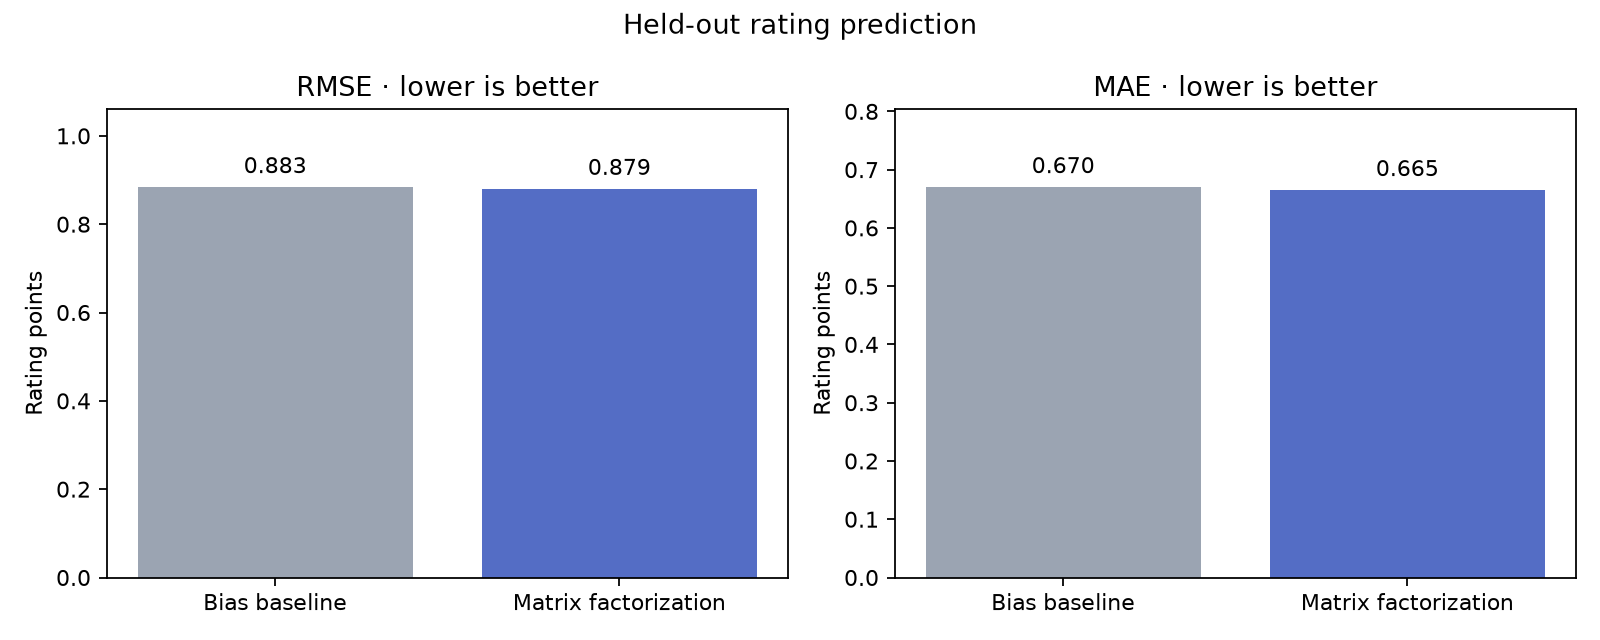

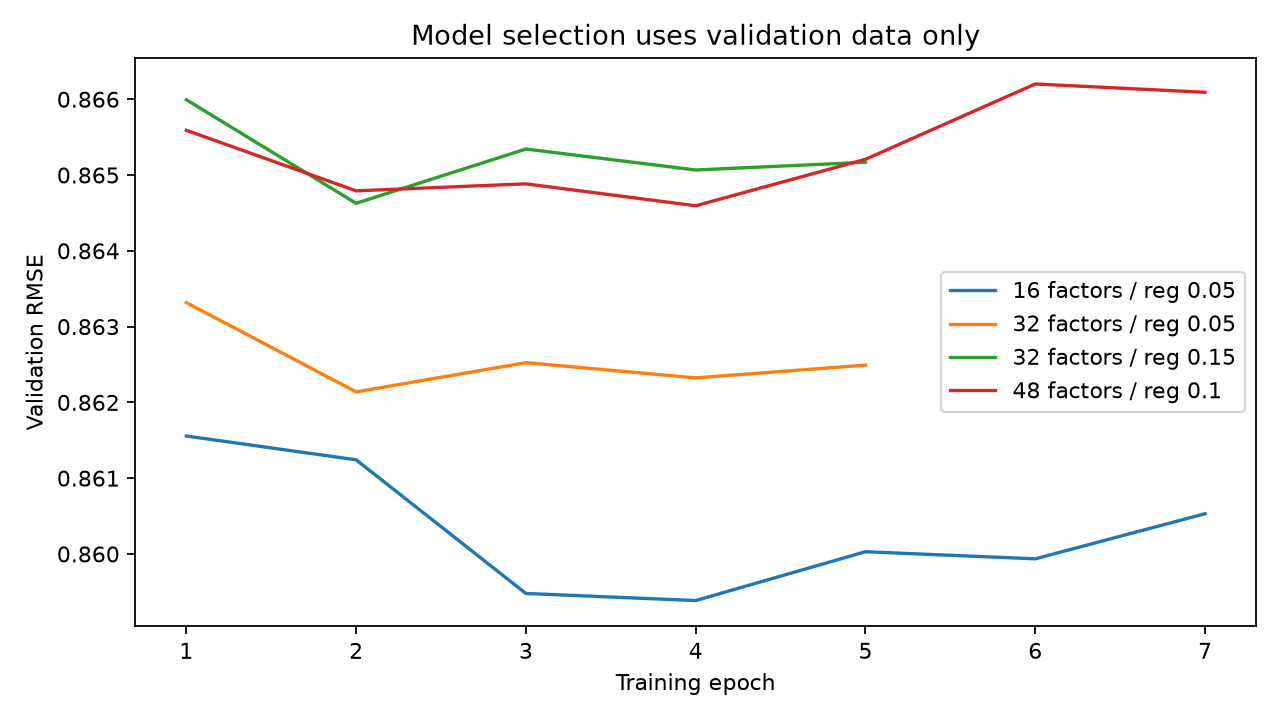

{'users': 200,
 'seed': 2026,
 'relevance': 'Held-out rating >=4; only users with at least one such rating. Unknown/unrated items have unknown relevance.',
 'candidate_policy': 'All movies with >=20 training ratings; excludes training and validation history. Unknown test movies remain in recall denominator.',
 'metrics': {'factor_model': {'precision_at_5': 0.009000000000000001,
   'recall_at_5': 0.0075264319014319014,
   'ndcg_at_5': 0.008629694494274748},
  'movie_average': {'precision_at_5': 0.024000000000000004,
   'recall_at_5': 0.016620526168344307,
   'ndcg_at_5': 0.029859503545631626}}}

In [4]:
metrics=json.loads(Path("outputs/metrics.json").read_text())
display(pd.DataFrame({k:metrics[k] for k in ["baseline","factor_model"]}).T)
display(Image(filename="outputs/evaluation.png"))
display(Image(filename="outputs/learning_curves.png"))
json.loads(Path("outputs/ranking_metrics.json").read_text())

## Top five predictions for three users

Exclude every movie already rated in the known user history. Restrict candidates to movies with at least 20 training ratings. This improves support but favors popular movies.

In [5]:
from recommend import recommend
examples=json.loads(Path("outputs/sample_recommendations.json").read_text())
for user in examples:
    print("User",user["id"])
    display(pd.DataFrame(recommend(user["id"])))

User 149632


,movieId,title,predicted_rating
0,171011,Planet Earth II (2016),4.434
1,170705,Band of Brothers (2001),4.368
2,1131,Jean de Florette (1986),4.354
3,202439,Parasite (2019),4.328
4,159817,Planet Earth (2006),4.298


User 139957


,movieId,title,predicted_rating
0,171011,Planet Earth II (2016),4.297
1,170705,Band of Brothers (2001),4.278
2,202439,Parasite (2019),4.225
3,2019,Seven Samurai (Shichinin no samurai) (1954),4.203
4,159817,Planet Earth (2006),4.185


User 18816


,movieId,title,predicted_rating
0,159817,Planet Earth (2006),4.762
1,171011,Planet Earth II (2016),4.742
2,202439,Parasite (2019),4.637
3,6669,Ikiru (1952),4.627
4,170705,Band of Brothers (2001),4.624


## New user onboarding

With at least three visitor ratings, hold movie factors fixed and solve a ridge least-squares problem for the visitor bias and latent vector (regularization 1). This is a practical fold-in heuristic; separate onboarding accuracy has not been established. The browser implementation is checked against NumPy’s independent linear solve. Ratings stay on the page and disappear on refresh.

## Limitations

Historical ratings are selected feedback, not random exposure or a guarantee of watching. Sparse new movies have no learned factors. Top-five ordering can be unstable when scores are close or clipped. No causal explanation or modern catalogue coverage is claimed. The sampled results do not represent the full 32M dataset.